<a href="https://colab.research.google.com/github/Abelwilson/CV/blob/main/Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Internet Speed Prediction

## Introduction

The aim of this project is to develop a machine learning model capable of predicting internet speed using the Internet Speed dataset from Kaggle.

This is a supervised regression problem, where the model learns the relationship between the available network-related features and the measured internet speed. Several regression approaches will be explored and compared based on their predictive performance.

The project will cover the following steps:

1. Data exploration and preprocessing
2. Feature analysis and selection
3. Model development
4. Hyperparameter tuning
5. Model evaluation and comparison

The models will primarily be evaluated using Root Mean Squared Error (RMSE), where a lower value indicates better prediction accuracy.

The final objective is to identify a suitable regression model and understand which features and hyperparameters have the greatest influence on internet speed prediction.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("getanmolgupta01/internet-speed")

print("Path to dataset files:", path)

100%|██████████| 515k/515k [00:00<00:00, 30.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/getanmolgupta01/internet-speed/versions/1


In [ ]:
import os
for dirname, _, filenames in os.walk(path):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/root/.cache/kagglehub/datasets/getanmolgupta01/internet-speed/versions/1/Internet Speed.csv


In [ ]:
data = pd.read_csv(dirname + "/" + filenames[0])

In [ ]:
data.head()

,Ping_latency,Download_speed,Upload_speed,Packet_loss_rate,Router_distance,Network_congestion,ISP_quality,Connection_type_DSL,Connection_type_Cable,Connection_type_Fiber,Signal_strength,Weather_conditions,Internet_speed
0,21.854305,42.395374,19.934759,0.999340,7.569985,1.369483,7.467012,0.000000,0.0,0.000000,76.190258,2.552049,730.336287
1,47.782144,49.976388,17.979781,1.493494,2.660608,1.243015,6.215047,2.373401,0.0,3.869607,70.945684,2.788454,994.148168
2,37.939727,86.182002,10.455388,1.125334,4.119757,3.416768,9.751490,1.509861,0.0,2.332773,83.994324,3.098587,2551.867438
3,31.939632,37.300417,31.148800,0.166605,6.969526,4.864465,4.532849,0.000000,0.0,1.608198,92.278904,4.479742,621.336539
4,12.020839,87.616720,24.877960,0.371160,5.338804,3.010885,7.114995,1.241954,0.0,2.693502,80.535702,4.190802,2612.315499


In [ ]:
data.shape

(5000, 13)

In [ ]:
data.describe()

,Ping_latency,Download_speed,Upload_speed,Packet_loss_rate,Router_distance,Network_congestion,ISP_quality,Connection_type_DSL,Connection_type_Cable,Connection_type_Fiber,Signal_strength,Weather_conditions,Internet_speed
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,27.357440,51.691277,26.066003,1.015369,5.578994,2.965295,6.504300,1.272947,1.256751,1.273640,84.948302,2.499880,1257.296163
std,13.033514,27.133568,13.956951,0.575612,2.598671,1.138216,2.018279,1.637940,1.625825,1.631132,8.609663,1.438197,927.617450
min,5.000524,5.005019,2.007572,0.000505,1.000433,1.000441,3.000039,0.000000,0.000000,0.000000,70.001406,0.003471,80.606669
25%,15.973826,28.478861,13.864032,0.525459,3.330062,1.988582,4.732669,0.000000,0.000000,0.000000,77.742714,1.244065,430.808067
50%,27.500388,51.167300,25.817462,1.024899,5.620063,2.963910,6.513309,0.032340,0.002561,0.031585,84.822169,2.511349,1018.976847
75%,38.664539,74.670302,38.509712,1.502211,7.819270,3.928608,8.237586,2.537834,2.507974,2.547957,92.345908,3.771796,1951.295923
max,49.987295,99.952993,49.990647,1.999850,9.999109,4.998928,9.998526,4.999453,4.999785,4.998248,99.998191,4.998094,3364.871190


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Ping_latency           5000 non-null   float64
 1   Download_speed         5000 non-null   float64
 2   Upload_speed           5000 non-null   float64
 3   Packet_loss_rate       5000 non-null   float64
 4   Router_distance        5000 non-null   float64
 5   Network_congestion     5000 non-null   float64
 6   ISP_quality            5000 non-null   float64
 7   Connection_type_DSL    5000 non-null   float64
 8   Connection_type_Cable  5000 non-null   float64
 9   Connection_type_Fiber  5000 non-null   float64
 10  Signal_strength        5000 non-null   float64
 11  Weather_conditions     5000 non-null   float64
 12  Internet_speed         5000 non-null   float64
dtypes: float64(13)
memory usage: 507.9 KB


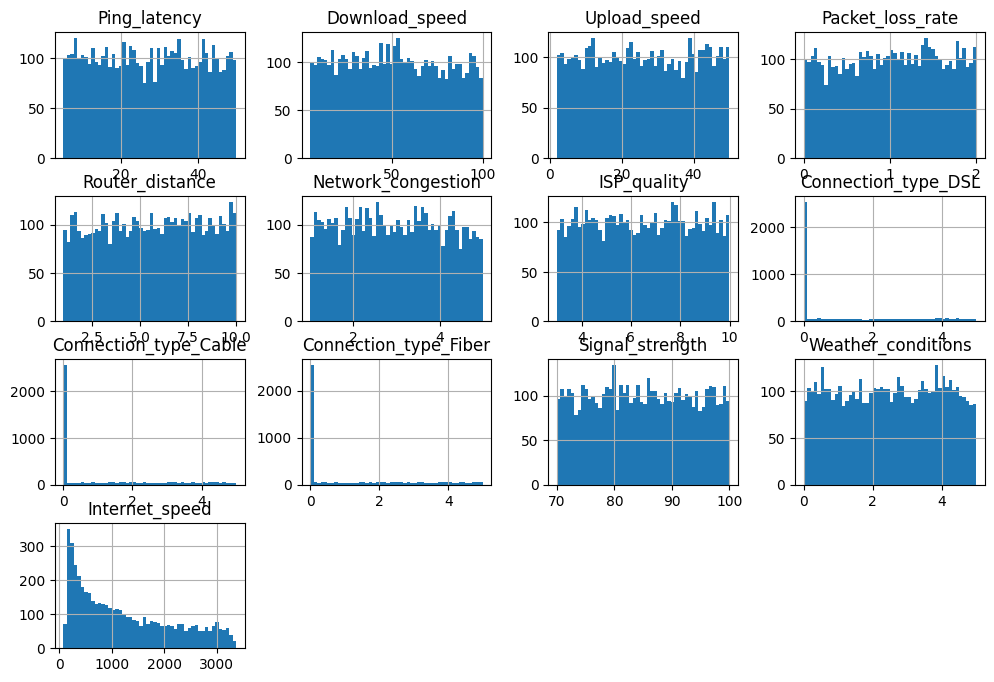

In [ ]:
data.hist(bins=50, figsize=(12, 8))
plt.show()

In [ ]:
print("Missing values in the dataset:")
data.isnull().sum()

Missing values in the dataset:


,0
Ping_latency,0
Download_speed,0
Upload_speed,0
Packet_loss_rate,0
Router_distance,0
Network_congestion,0
ISP_quality,0
Connection_type_DSL,0
Connection_type_Cable,0
Connection_type_Fiber,0


In [ ]:
categoricals = data.select_dtypes(include=['object']).columns.tolist()
numericals = data.select_dtypes(include=['int64', 'float64']).columns.tolist()
categoricals, numericals

([],
 ['Ping_latency',
  'Download_speed',
  'Upload_speed',
  'Packet_loss_rate',
  'Router_distance',
  'Network_congestion',
  'ISP_quality',
  'Connection_type_DSL',
  'Connection_type_Cable',
  'Connection_type_Fiber',
  'Signal_strength',
  'Weather_conditions',
  'Internet_speed'])

In [ ]:
X = data.drop(columns=['Internet_speed'])
y = data['Internet_speed']
numericals.remove('Internet_speed')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train[numericals] = scaler.fit_transform(X_train[numericals])
X_test[numericals]  = scaler.transform(X_test[numericals])

In [ ]:
corr_matrix = data.corr(numeric_only=True)
corr_matrix["Internet_speed"].sort_values(
ascending=False
)

,Internet_speed
Internet_speed,1.000000
Download_speed,0.975699
Connection_type_DSL,0.020906
Signal_strength,0.011692
Router_distance,0.010041
Weather_conditions,0.008200
Connection_type_Cable,0.007339
Connection_type_Fiber,0.000194
Network_congestion,0.000018
Ping_latency,-0.000861


In [ ]:
categoricals = data.select_dtypes(include=['object']).columns.tolist()
numericals = data.select_dtypes(include=['int64', 'float64']).columns.tolist()
categoricals, numericals

([],
 ['Ping_latency',
  'Download_speed',
  'Upload_speed',
  'Packet_loss_rate',
  'Router_distance',
  'Network_congestion',
  'ISP_quality',
  'Connection_type_DSL',
  'Connection_type_Cable',
  'Connection_type_Fiber',
  'Signal_strength',
  'Weather_conditions',
  'Internet_speed'])

In [ ]:
X = data.drop(columns=['Internet_speed'])
y = data['Internet_speed']
numericals.remove('Internet_speed')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train[numericals] = scaler.fit_transform(X_train[numericals])
X_test[numericals]  = scaler.transform(X_test[numericals])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (4000, 12)
Testing features: (1000, 12)
Training target: (4000,)
Testing target: (1000,)


In [ ]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()

lin_reg.fit(X_train, y_train)

print("Linear Regression training completed.")

Linear Regression training completed.


In [ ]:
y_pred = lin_reg.predict(X_test)
comparison = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": y_pred[:10]
})

comparison

,Actual,Predicted
0,241.807717,-22.699875
1,775.312932,983.054853
2,2272.789256,2244.230938
3,1057.703588,1244.276123
4,480.917746,560.901710
5,675.005107,832.137203
6,1550.482305,1720.303361
7,1458.247499,1637.401634
8,2383.032847,2316.867268
9,1165.999518,1410.957037


In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared (R²):", r2)

Mean Absolute Error (MAE): 176.22974145879078
Root Mean Squared Error (RMSE): 202.93413644042036
R-squared (R²): 0.9524121953347189


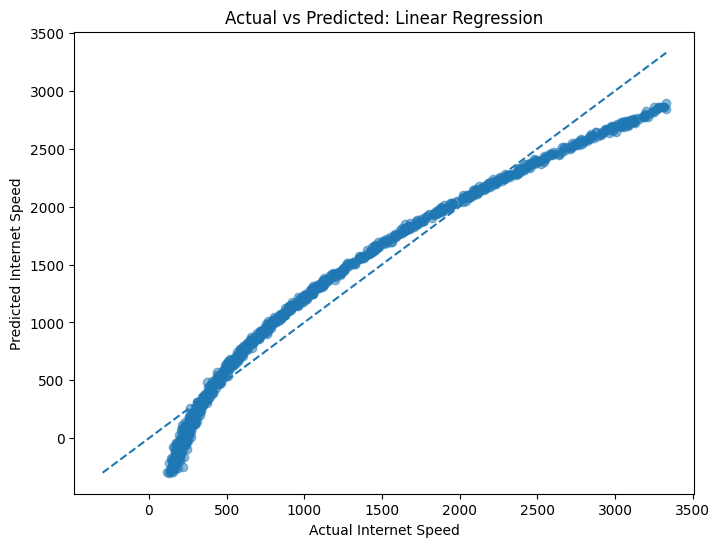

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Internet Speed")
plt.ylabel("Predicted Internet Speed")
plt.title("Actual vs Predicted: Linear Regression")
plt.show()

Linear Regression: Dimma<br>
Decision Tree: Abel<br>
SVR: Romain<br>
Random Forest: Clovis<br>



In [ ]:
from sklearn.svm import SVR

rbf_svr = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svr",
        SVR(
            kernel="rbf",
            C=100,
            gamma="scale",
            epsilon=0.1
        )
    )
])

rbf_svr.fit(
    X_train,
    y_train
)

Pipeline(steps=[('scaler', StandardScaler()), ('svr', SVR(C=100))])

In [ ]:
y_pred = rbf_svr.predict(
    X_test
)

comparison = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": y_pred[:10]
})

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

comparison

,Actual,Predicted
0,241.807717,275.378584
1,775.312932,798.945870
2,2272.789256,2199.085189
3,1057.703588,1053.452599
4,480.917746,459.863737
5,675.005107,720.848494
6,1550.482305,1593.770718
7,1458.247499,1509.750424
8,2383.032847,2265.542473
9,1165.999518,1152.225524


In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared (R²):", r2)

Mean Absolute Error (MAE): 99.57538199740151
Root Mean Squared Error (RMSE): 163.92253857852205
R-squared (R²): 0.9689499147428371


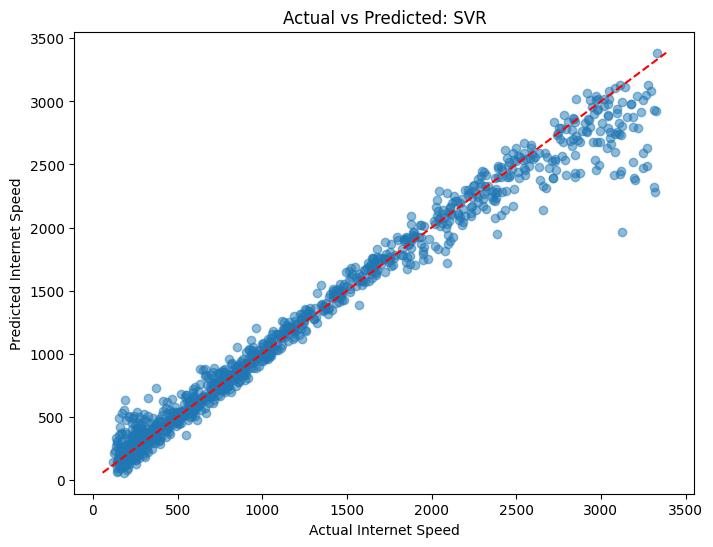

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="red",
    label="Perfect predictions"
)

plt.xlabel("Actual Internet Speed")
plt.ylabel("Predicted Internet Speed")
plt.title("Actual vs Predicted: SVR")
plt.show()

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from scipy.stats import loguniform, uniform

rbf_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf"))
])

param_distributions = {
    "svr__C": loguniform(0.1, 1000),
    "svr__gamma": loguniform(1e-4, 1),
    "svr__epsilon": uniform(0.01, 0.99)
}

random_search = RandomizedSearchCV(
    estimator=rbf_svr,
    param_distributions=param_distributions,
    n_iter=40,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 40 candidates, totalling 120 fits


RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                             ('svr', SVR())]),
                   n_iter=40, n_jobs=-1,
                   param_distributions={'svr__C': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7a95621b9be0>,
                                        'svr__epsilon': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7a9560242e90>,
                                        'svr__gamma': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7a9560242850>},
                   random_state=42, scoring='neg_root_mean_squared_error',
                   verbose=1)

In [ ]:
print("Best parameters:", random_search.best_params_)
print("Best CV RMSE:", -random_search.best_score_)

Best parameters: {'svr__C': np.float64(624.5139574743067), 'svr__epsilon': np.float64(0.9659757127438138), 'svr__gamma': np.float64(0.17123375973163968)}
Best CV RMSE: 171.2126845573364


In [ ]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

best_svr = random_search.best_estimator_
y_pred = best_svr.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", root_mean_squared_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))

MAE: 90.79810316894334
RMSE: 149.57073751672706
R²: 0.9741489180162067


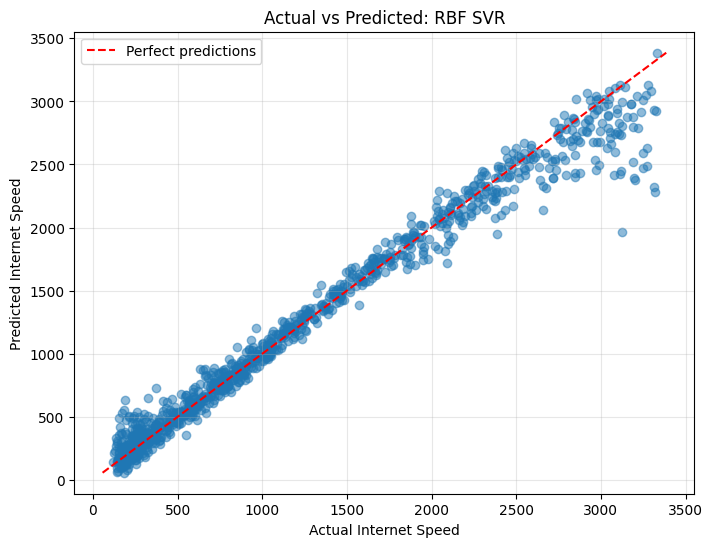

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="red",
    label="Perfect predictions"
)

plt.xlabel("Actual Internet Speed")
plt.ylabel("Predicted Internet Speed")
plt.title("Actual vs Predicted: RBF SVR")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Random forest Model: Clovis**

In [ ]:
forest_reg = RandomForestRegressor(n_estimators=100,random_state=42)
forest_scores = cross_val_score(forest_reg, X_train, y_train,
                                scoring="neg_mean_squared_error", cv=10)

KeyboardInterrupt: 

In [ ]:
forest_rmse_scores = np.sqrt(-forest_scores)
print("Mean␣RMSE:",
forest_rmse_scores.mean())
print("Standard␣deviation:",
forest_rmse_scores.std())

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_features": [6, 9, 12],
}

grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid,
                           cv=10, scoring="neg_mean_squared_error", n_jobs=-1)
grid_search.fit(X_train, y_train)

print(grid_search.best_params_)
print(np.sqrt(-grid_search.best_score_))

After searching for the best hyperparameters it seems like the initial ones were already good as the difference in mean RMSE between n_estimators=100 and n_estimators=200 is only of around 0.06 Mbps.

These results are likely inflated by Download_speed which is higly correlated to Internet_speed (see Correlation Matrix)

In [ ]:
print("Target mean:", y_train.mean())
print("Target std:", y_train.std())
print("Forest RMSE:", 22.67)

from sklearn.metrics import r2_score
from sklearn.model_selection import cross_val_predict
pred = cross_val_predict(grid_search.best_estimator_, X_train, y_train, cv=5, n_jobs=-1)
print("R2:", r2_score(y_train, pred))

In [ ]:
X_train_clean = X_train.drop(columns=["Download_speed"])

scores = cross_val_score(RandomForestRegressor(n_estimators=100, random_state=42),
                         X_train_clean, y_train,
                         scoring="neg_mean_squared_error", cv=10, n_jobs=-1)
rmse = np.sqrt(-scores)
print("Mean RMSE:", rmse.mean())
print("Std:", rmse.std())

If we remove Download_speed from the training data, the random forest model shows a mean RMSE (944) worse than always guessing the average (927 = target std) which shows that initially the dataset's predictive information about Internet_speed is all contained in the Download_speed feature.

In [ ]:

plt.scatter(X_train["Download_speed"], y_train, s=3, alpha=0.4)
plt.xlabel("Download_speed")
plt.ylabel("Internet_speed")
plt.show()

In [ ]:
plt.scatter(X_train["Signal_strength"], y_train, s=3, alpha=0.4)
plt.xlabel("Signal_strength")
plt.ylabel("Internet_speed")
plt.show()

Internet_speed rises smoothly and non-linearly with Download_speed and carries most of the information which is not the case of other features (like Signal_strength for example)